In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import hashlib
import imageio
import io
import os
from scipy.stats import multivariate_normal
import warnings
warnings.filterwarnings("ignore")
from gmm import MyGMM

# Deterministic seed based on username
username = "konda.rithvika"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed:", seed)


Seed: 2226785795


In [5]:


def load_image(path):
    """
    Load an image from a given file path and return it as a NumPy RGB array.
    """
    if not os.path.exists(path):
        raise FileNotFoundError(f"Image not found: {path}")
    img = Image.open(path).convert("RGB")
    return np.array(img)


def flatten_image(img):
    """
    Flatten a 3D image array into a 2D array of pixels.

    Args:
        img (np.ndarray): Input image of shape (H, W, 3).

    Returns:
        np.ndarray: Flattened pixel array of shape (H*W, 3) with float values.
    """
    return img.reshape(-1, 3).astype(float)


def map_clusters_to_colors(means, target_colors):
    """
    Map each cluster mean to the closest target color.
    This ensures consistent coloring across segmentations
    (e.g., water → blue, vegetation → green, land → brown).

    Args:
        means (np.ndarray): Array of cluster mean RGB values.
        target_colors (list): List of fixed RGB colors to assign.

    Returns:
        dict: Mapping from cluster index to assigned target color.
    """
    # Map each cluster mean to the closest target color (e.g., water, vegetation, land)
    mapping = {}
    used = set()
    for i, mean in enumerate(means):
        # Compute distances from cluster mean to each target color
        
        dists = [np.linalg.norm(mean - color) for color in target_colors]
        # Assign to closest unused color
        # Sort distances to find nearest unused target color
        
        sorted_idx = np.argsort(dists)
        for idx in sorted_idx:
            if idx not in used:
                mapping[i] = tuple(target_colors[idx])
                used.add(idx)
                break
    return mapping


def make_frame_three_panels(original_rgb, segmented_rgb, gmm, iter_idx, figsize=(15, 6)):
    
    # Create combined figure with 3 panels: original | segmented | log-likelihood
    fig, axes = plt.subplots(1, 3, figsize=figsize)
     # Original image
    axes[0].imshow(original_rgb.astype(np.uint8))
    axes[0].set_title(f"Original")
    axes[0].axis("off")
    
     # Segmented image

    axes[1].imshow(segmented_rgb.astype(np.uint8))
    axes[1].set_title(f"Segmented (iter {iter_idx})")
    axes[1].axis("off")

    # Log-likelihood progression
    axes[2].plot(gmm.log_likelihoods, marker="o", linestyle="--")
    axes[2].set_xlabel("Iteration")
    axes[2].set_ylabel("Log Likelihood")
    axes[2].set_title("Log Likelihood")
    axes[2].grid(True)
    
    fig.text(
            0.5, 0.98,"Rithvika",
            ha="center", va="top",
            fontsize=12, color="white",
            bbox=dict(facecolor="black", alpha=0.6, pad=4)
        )

    # Convert figure to image (PNG buffer)

    buf = io.BytesIO()
    plt.tight_layout()
    fig.savefig(buf, format="png")
    plt.close(fig)
    buf.seek(0)
    frame = imageio.v2.imread(buf)
    buf.close()
    return frame


# Main function that produces both the static segmented images (using fixed RGB mapping)
# and MP4 videos where the segmented panel uses the current component means (mean colors).

def segment_image_and_create_video(img_path, out_mp4_path, fixed_colors, gmm_kwargs, fps=2, max_frames=None):
    """
    Segment an image using a custom Gaussian Mixture Model (MyGMM).
    Produces:
      1. A static segmented image using fixed RGB color mapping.
      2. An MP4 video showing iterative segmentation evolution.

    Args:
        img_path (str): Path to the input image.
        out_mp4_path (str): Path to save the output MP4 video.
        fixed_colors (list): List of fixed RGB colors for static segmentation.
        gmm_kwargs (dict): Keyword arguments for MyGMM initialization.
        fps (int): Frames per second for the MP4 video.
        max_frames (int, optional): Maximum number of frames to generate.

    Returns:
        tuple: Filenames of the original image, fixed-color segmented image, and video.
    """
    img = load_image(img_path)
    X = flatten_image(img)

    # 1) Static segmentation using provided fixed RGB color mapping (first part request)
    gmm_static = MyGMM(**gmm_kwargs)
    # Fit but do not collect frames - we only need final labels to show fixed-color segmentation
    gmm_static.fit(X)
    gamma_static = gmm_static.compute_responsibilities(X)
    labels_static = np.argmax(gamma_static, axis=1)
    mapping_fixed = map_clusters_to_colors(gmm_static.means, fixed_colors)
    segmented_fixed = np.array([mapping_fixed[label] for label in labels_static]).reshape(img.shape)

    # Save/print the original and fixed-color segmented images (as PNG)
    base = os.path.splitext(os.path.basename(img_path))[0]
    orig_save = f"{base}_original.png"
    seg_fixed_save = f"{base}_segmented_fixed_colors.png"
    Image.fromarray(img.astype(np.uint8)).save(orig_save)
    Image.fromarray(segmented_fixed.astype(np.uint8)).save(seg_fixed_save)
    print(f"Saved: {orig_save}")
    print(f"Saved: {seg_fixed_save}")
        
    # Plot inline
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(img)
    ax[0].set_title("Original Image")
    ax[0].axis("off")

    ax[1].imshow(segmented_fixed.astype(np.uint8))
    ax[1].set_title("Segmented (Fixed Colors)")
    ax[1].axis("off")

    plt.suptitle(f"Segmentation Result for {os.path.basename(img_path)} - kondarithvika")
    plt.tight_layout()
    plt.show()

    # 2) Dynamic visualization MP4 (each frame = one EM iteration) using mean colors for segmentation
    gmm = MyGMM(**gmm_kwargs)
    frames = []

    # We'll write frames directly to an mp4 writer to avoid huge memory usage
    writer = imageio.get_writer(out_mp4_path, fps=fps, codec='libx264', quality=8)

    def callback(i, model, X_data):
        """
        Callback executed after each EM iteration.
        Generates a video frame with the current segmentation state.
        """
        # compute labels using current parameters
        gamma = model.compute_responsibilities(X_data)
        labels = np.argmax(gamma, axis=1)
        # Use the current means as the colors (rounded and clipped to [0,255])
        means_colors = np.clip(np.rint(model.means), 0, 255).astype(np.uint8)
        segmented_mean = np.array([tuple(means_colors[label]) for label in labels]).reshape(img.shape)
        frame = make_frame_three_panels(img, segmented_mean, model, i)
        writer.append_data(frame)
        # optional early stop to limit frames
        if max_frames is not None and (i + 1) >= max_frames:
            return

    # Fit GMM and write frames during training
    gmm.fit(X, callback=callback)

    # ensure final frame (final means)
    gamma_final = gmm.compute_responsibilities(X)
    labels_final = np.argmax(gamma_final, axis=1)
    means_colors_final = np.clip(np.rint(gmm.means), 0, 255).astype(np.uint8)
    segmented_final = np.array([tuple(means_colors_final[label]) for label in labels_final]).reshape(img.shape)
    final_frame = make_frame_three_panels(img, segmented_final, gmm, len(gmm.log_likelihoods) - 1)
    writer.append_data(final_frame)

    writer.close()
    print(f"Saved MP4: {out_mp4_path}")

    return orig_save, seg_fixed_save, out_mp4_path


Saved: satellite_1_original.png
Saved: satellite_1_segmented_fixed_colors.png


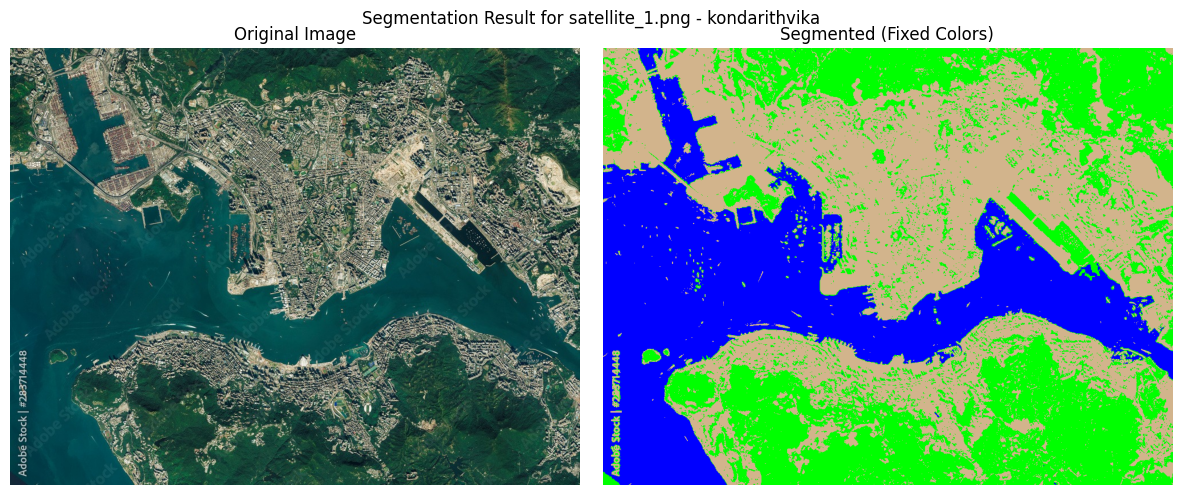

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1500, 600) to (1504, 608) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
[rawvideo @ 0x1b7d8040] Stream #0: not enough frames to estimate rate; consider increasing probesize


Saved MP4: satellite_1_segmentation.mp4
Saved: satellite_2_original.png
Saved: satellite_2_segmented_fixed_colors.png


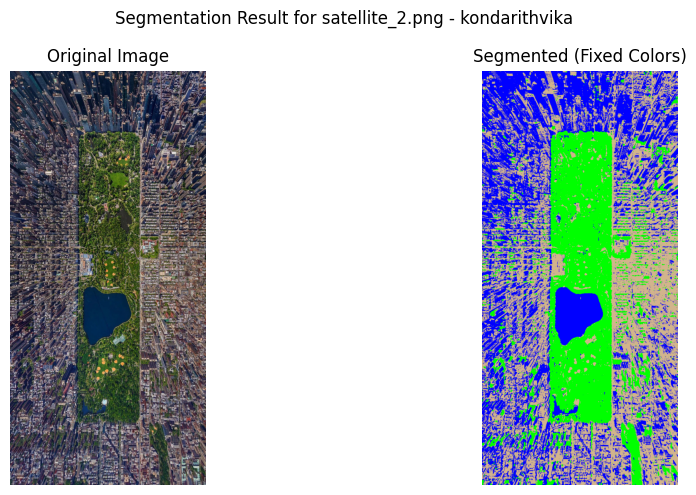

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (1500, 600) to (1504, 608) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
[rawvideo @ 0x45642040] Stream #0: not enough frames to estimate rate; consider increasing probesize


Saved MP4: satellite_2_segmentation.mp4
Done. Files produced:
satellite_1_original.png satellite_1_segmented_fixed_colors.png satellite_1_segmentation.mp4
satellite_2_original.png satellite_2_segmented_fixed_colors.png satellite_2_segmentation.mp4


In [6]:
colors = np.array([
        [0, 0, 255],    # Blue -> water (fixed color for static image)
        [0, 255, 0],    # Green -> vegetation
        [210, 180, 140] # Tan -> land
    ])

img1_path = "satellite_1.png"
img2_path = "satellite_2.png"

gmm_kwargs_1 = dict(k=3, max_iter=50, random_state=seed, tol=1e-4)
gmm_kwargs_2 = dict(k=3, max_iter=50, random_state=seed + 1, tol=1e-4)

    # Process image 1 (save original + fixed-color segmented PNGs, and an MP4 with mean-color iterations)
orig1, seg1_fixed, mp4_1 = segment_image_and_create_video(img1_path, "satellite_1_segmentation.mp4", colors, gmm_kwargs_1, fps=2)

    # Process image 2
orig2, seg2_fixed, mp4_2 = segment_image_and_create_video(img2_path, "satellite_2_segmentation.mp4", colors, gmm_kwargs_2, fps=2)


print("Done. Files produced:")
print(orig1, seg1_fixed, mp4_1)
print(orig2, seg2_fixed, mp4_2)


### LINKS
1st : https://iiithydstudents-my.sharepoint.com/:v:/g/personal/konda_rithvika_students_iiit_ac_in/Ea_gZtdKDGVAtkepbk13Pd8BOxORkooY1PJM7u46Qp9Fmg?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=zuycTt


2nd : https://iiithydstudents-my.sharepoint.com/:v:/g/personal/konda_rithvika_students_iiit_ac_in/EZFvS0sFc5VLhdnnVU3xgB8BC074BaI3Ki8fVKluDTN0RQ?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=7PaPwJ

- colors :
- vegetation - green
- Land - sand color
- Water - Blue